# Clasificación de suelo con imágenes satelitales (EuroSAT RGB)

Proyecto de **Machine Learning** para clasificar imágenes satelitales de 64×64 píxeles en 10 categorías:

- AnnualCrop (Terrenos para cultivos anuales)
- Forest (Bosque)
- HerbaceousVegetation (Vegetación herbácea)
- Highway (Autopistas y carreteras)
- Industrial (Zonas industriales)
- Pasture (Terrenos de pastoreo)
- PermanentCrop (Terrenos para cultivos permanentes)
- Residential (Zonas residenciales)
- River (Ríos)
- SeaLake (Mares y lagos)

Se compararán los siguientes modelos:

- **Redes Neuronales Convolucionales (CNN)**: un modelo base y uno mejorado con Dropout y Data Augmentation.
- **Transfer Learning**: una red MobileNetV2 preentrenada con ImageNet y adaptada al problema.
- **Modelos basados en árboles**: árbol de decisión base, árbol con poda y Random Forest.

**Nota:** los entrenamientos de las redes neuronales incluyen componentes aleatorios (inicialización de pesos, orden de los lotes, Dropout y Data Augmentation), por lo que los valores pueden variar levemente entre ejecuciones. Los valores mencionados en el texto corresponden a las salidas que se muestran en este notebook.

### 1. Importación de librerías y verificación del entorno

Se importan todas las dependencias necesarias para el proyecto y se verifican las versiones de las librerías principales.

In [1]:
# Importación de librerías
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torchvision
from torchvision import datasets

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.applications import MobileNetV2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Se oculta el aviso de MobileNetV2 sobre el tamaño de entrada (se explica más adelante)
warnings.filterwarnings("ignore", message=".*input_shape.*")

# Verificación de versiones
print("torchvision:", torchvision.__version__)
print("tensorflow:", tf.__version__)
print("keras:", keras.__version__)

torchvision: 0.29.1+cpu
tensorflow: 2.21.0
keras: 3.15.1


### 2. Carga del dataset

EuroSAT contiene 27.000 imágenes RGB de 64×64 píxeles tomadas por el satélite Sentinel-2, etiquetadas en 10 clases. Se descarga con torchvision y cada imagen se convierte a un array de NumPy de forma (64, 64, 3), es decir, alto × ancho × 3 canales de color (R, G, B).

Los valores de cada píxel se mantienen en su escala original (0-255).

Al terminar la carga se obtienen dos arrays:

- **X** → todas las imágenes, con forma (27000, 64, 64, 3)
- **y** → la clase de cada imagen, con forma (27000,), con valores de 0 a 9

El escalado a 0-1, que ayuda a que el entrenamiento de la red sea más estable y rápido, se aplica más adelante dentro del modelo de red neuronal. Los modelos de árboles no lo necesitan.

In [2]:
dataset = datasets.EuroSAT(root="data", download=True)

X, y = [], []
for imagen, etiqueta in dataset:
    X.append(np.array(imagen))
    y.append(etiqueta)

X = np.stack(X)   # (27000, 64, 64, 3)
y = np.array(y)   # (27000,)

print("Cantidad de imágenes:", len(X))
print("Clases:", dataset.classes)
print("Forma de X:", X.shape, "| dtype:", X.dtype)

Cantidad de imágenes: 27000
Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Forma de X: (27000, 64, 64, 3) | dtype: uint8


### 3. Visualización de ejemplos

A continuación, se visualizarán dos ejemplos aleatorios del dataset junto con sus etiquetas para conocer cómo son las imágenes con las que se va a trabajar.

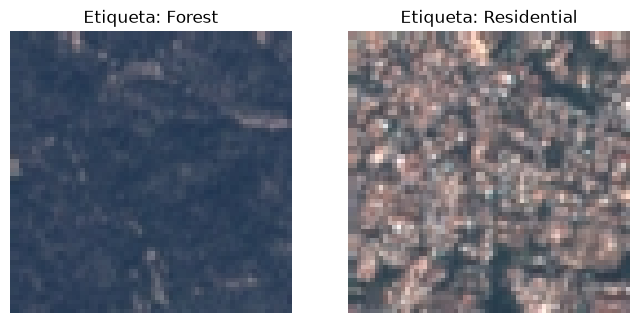

In [3]:
random.seed(1)

plt.figure(figsize=(8, 4))
indices_ejemplos = random.sample(range(len(X)), 2)

for i, idx in enumerate(indices_ejemplos):
    plt.subplot(1, 2, i + 1)
    plt.imshow(X[idx])
    plt.title(f"Etiqueta: {dataset.classes[y[idx]]}")
    plt.axis("off")

plt.show()

### 4. Distribución de clases

Antes de modelar se revisa cuántas imágenes hay por clase. Si hubiera un desbalance fuerte, el accuracy podría ser engañoso.

In [4]:
pd.Series([dataset.classes[i] for i in y]).value_counts()

AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Residential             3000
SeaLake                 3000
Highway                 2500
Industrial              2500
PermanentCrop           2500
River                   2500
Pasture                 2000
Name: count, dtype: int64

Las clases están levemente desbalanceadas: la mayoría tiene entre 2500 y 3000 imágenes, aunque `Pasture` tiene 2000. No es un desbalance grave, pero además del accuracy conviene mirar el F1 por clase.

### 5. División del dataset

Se dividirá el dataset en tres conjuntos: entrenamiento (60%), validación (20%) y testeo (20%). Se usa `stratify` para que cada conjunto mantenga la misma proporción de clases que el dataset original.

- **Entrenamiento:** el modelo aprende a partir de estos datos.
- **Validación:** se usa para comparar configuraciones y decidir cuándo frenar el entrenamiento.
- **Testeo:** se usa solo al final, para medir el desempeño sobre datos nunca vistos. Las métricas obtenidas a partir de este dataset son las que se esperan obtener en producción.

In [5]:
# 60% entrenamiento, 40% restante para validación y testeo
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=1, stratify=y)

# El 40% restante se divide en partes iguales
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=1, stratify=y_temp)

del X, X_temp, y_temp  # libera memoria

### 6. Cantidad de ejemplos por conjunto

In [6]:
print("Entrenamiento:", X_train.shape)
print("Validación:   ", X_val.shape)
print("Testeo:       ", X_test.shape)

Entrenamiento: (16200, 64, 64, 3)
Validación:    (5400, 64, 64, 3)
Testeo:        (5400, 64, 64, 3)


### 7. Función para graficar las curvas de entrenamiento

Se define una función que grafica la accuracy y la pérdida (loss) por época, tanto en entrenamiento como en validación. Sirve para detectar visualmente el **overfitting**: cuando la curva de entrenamiento sigue mejorando pero la de validación se estanca o empeora.

Se recuerda que en cada época (epoch):
- **Accuracy:** mide el porcentaje (o proporción) de aciertos que tuvo el modelo al predecir sobre el conjunto de datos.
- **Loss:** mide el error promedio cometido por el modelo según la función de costo (cuanto más cercano a 0, menor es el error).

In [7]:
def graficar_historial(historial, titulo):
    epocas = range(1, len(historial['accuracy']) + 1)
    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epocas, historial['accuracy'], label="Entrenamiento")
    plt.plot(epocas, historial['val_accuracy'], label="Validación")
    plt.title(f"Accuracy - {titulo}")
    plt.xlabel("Época")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epocas, historial['loss'], label="Entrenamiento")
    plt.plot(epocas, historial['val_loss'], label="Validación")
    plt.title(f"Loss - {titulo}")
    plt.xlabel("Época")
    plt.legend()

    plt.show()

# Modelo 1: Redes Neuronales

Se crearán dos modelos, uno base y uno mejorado con la implementación de las técnicas **DropOut** y **Data Augmentation**.

### 1. Creación del modelo

Se define una **Red Neuronal Convolucional (CNN)** para clasificar imágenes de 64x64 px (RGB) en 10 clases:

- **Arquitectura:**
    - **Entrada y normalización:** capa `Input` (64, 64, 3) y `Rescaling` para llevar los valores de píxeles a [0, 1].
    - **Extracción de características:** 3 bloques convolucionales (`Conv2D` con activación `ReLU` + `MaxPooling2D`) de 32, 64 y 128 filtros respectivamente.
    - **Clasificador:** capa `Flatten`, una capa densa intermedia de 128 neuronas (`ReLU`) y una capa de salida de 10 neuronas (salida en logits).
- **Compilación:** optimizador `Adam`, función de pérdida `SparseCategoricalCrossentropy(from_logits=True)` y métrica `accuracy`.
- **Estrategia de entrenamiento:** `ModelCheckpoint` guarda el modelo con mejor `val_accuracy` y `EarlyStopping` detiene el entrenamiento si no hay mejoras tras 10 épocas (restaurando los mejores pesos).

In [8]:
def entrenar_red(X_train, y_train, X_val, y_val, epochs=100):
    keras.utils.set_random_seed(1)

    model = keras.Sequential([
        # Entrada y Normalización
        keras.Input(shape=(64, 64, 3)),
        layers.Rescaling(1./255), # escala 0-255 a 0-1

        # Extracción de características
        # Bloque 1: detecta características básicas
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(),

        # Bloque 2: detecta patrones intermedios
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(),

        # Bloque 3: detecta características complejas del objeto
        layers.Conv2D(128, 3, activation='relu'),
        layers.MaxPooling2D(),

        # Clasificador (Capas densas / Fully Connected)
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10) # logits (10 clases)
    ])

    # Compilación del modelo
    model.compile(
        optimizer='adam',
        loss=SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

    # Estrategia de entrenamiento (ModelCheckpoint y EarlyStopping)
    checkpoint = ModelCheckpoint(
        "mejor_modelo.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    )

    early = keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        restore_best_weights=True
    )

    # Entrenamiento
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=64,
        callbacks=[early, checkpoint]
    )

    return history.history, model

### 2. Entrenamiento del modelo 

In [9]:
historial, modelo = entrenar_red(X_train, y_train, X_val, y_val)

Epoch 1/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 19s 69ms/step - accuracy: 0.4595 - loss: 1.3967 - val_accuracy: 0.6202 - val_loss: 1.0831
Epoch 2/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 17s 66ms/step - accuracy: 0.6490 - loss: 0.9635 - val_accuracy: 0.7148 - val_loss: 0.8001
Epoch 3/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 17s 66ms/step - accuracy: 0.7067 - loss: 0.8067 - val_accuracy: 0.6617 - val_loss: 0.9135
Epoch 4/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 17s 67ms/step - accuracy: 0.7441 - loss: 0.7019 - val_accuracy: 0.7189 - val_loss: 0.7771
Epoch 5/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 17s 67ms/step - accuracy: 0.7674 - loss: 0.6400 - val_accuracy: 0.7894 - val_loss: 0.5978
Epoch 6/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 17s 66ms/step - accuracy: 0.7820 - loss: 0.5940 - val_accuracy: 0.6994 - val_loss: 0.8528
Epoch 7/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 17s 66ms/step - accuracy: 0.7965 - loss: 0.5609 - val_accuracy: 0.7183 - val_loss: 0.7795
Epoch 8/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 18s 69ms/step - accuracy: 0.8078 - loss: 0

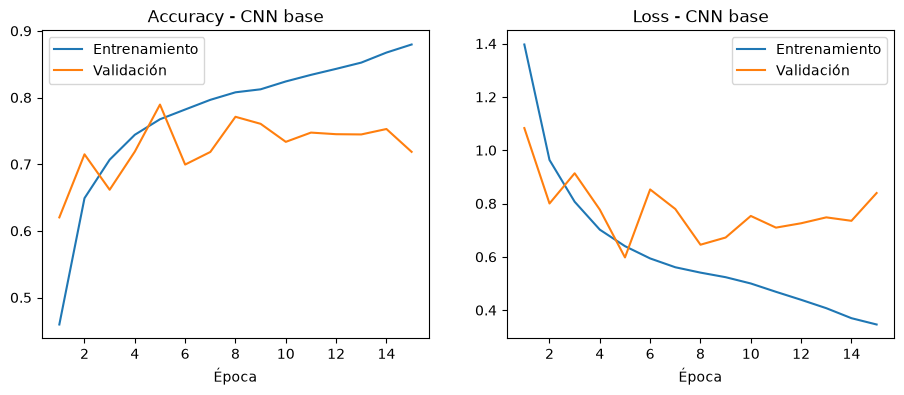

In [10]:
graficar_historial(historial, "CNN base")

In [11]:
mejor_modelo = keras.models.load_model("mejor_modelo.keras")

El entrenamiento frenó en la época 15 debido a que la val_accuracy no mejoraba. Se ha almacenado el mejor modelo en la variable **mejor_modelo**, que se corresponde al de la época 5.

Se observa que la accuracy de entrenamiento sigue subiendo (hasta ~88%) mientras que la de validación se estanca alrededor de 70-77%. Además, el val_loss tiende a subir a partir de la época 5 (pasando de 0.60 a 0.84). Esa brecha creciente indica que la red memoriza el conjunto de entrenamiento y genera muchos errores con el conjunto de validación, problema conocido como **overfitting** o **sobreajuste**.

Se prueba a continuación con **Dropout** y **Data Augmentation**.

### 3. Optimización de la Red Neuronal: Implementación de Dropout y Data Augmentation

Para solucionar el inconveniente mencionado arriba, se desarrollará un nuevo modelo aplicando:

- **Dropout:** técnica de regularización que apaga neuronas aleatoriamente durante el entrenamiento para reducir el sobreajuste.
- **Data Augmentation (aumento de datos):** generación de variaciones en las imágenes (giros y rotaciones) para enriquecer el conjunto de entrenamiento y mejorar la capacidad de generalización del modelo.

In [12]:
def entrenar_red_mejorada(X_train, y_train, X_val, y_val, epochs=100):
    keras.utils.set_random_seed(1)

    model = keras.Sequential([
        keras.Input(shape=(64, 64, 3)),

        # Aumento de datos (solo se aplica durante el entrenamiento)
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),

        layers.Rescaling(1./255),

        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation='relu'),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(10)
    ])

    model.compile(
        optimizer='adam',
        loss=SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

    checkpoint = ModelCheckpoint(
        "mejor_modelo_mejorado.keras", 
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    )

    early = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=10, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=64,
        callbacks=[early, checkpoint]
    )

    return history.history, model

### 4. Entrenamiento del modelo mejorado

In [13]:
historial_mejorado, modelo_mejorado = entrenar_red_mejorada(X_train, y_train, X_val, y_val)

Epoch 1/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 21s 74ms/step - accuracy: 0.3521 - loss: 1.6615 - val_accuracy: 0.5044 - val_loss: 1.2479
Epoch 2/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - accuracy: 0.5270 - loss: 1.2559 - val_accuracy: 0.6104 - val_loss: 1.1389
Epoch 3/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 20s 80ms/step - accuracy: 0.6356 - loss: 1.0261 - val_accuracy: 0.6813 - val_loss: 0.9138
Epoch 4/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - accuracy: 0.6784 - loss: 0.9060 - val_accuracy: 0.7141 - val_loss: 0.8453
Epoch 5/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 19s 76ms/step - accuracy: 0.7080 - loss: 0.8312 - val_accuracy: 0.7519 - val_loss: 0.6938
Epoch 6/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 20s 77ms/step - accuracy: 0.7122 - loss: 0.8108 - val_accuracy: 0.7443 - val_loss: 0.7323
Epoch 7/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - accuracy: 0.7276 - loss: 0.7636 - val_accuracy: 0.7689 - val_loss: 0.6394
Epoch 8/100
254/254 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - accuracy: 0.7428 - loss: 0

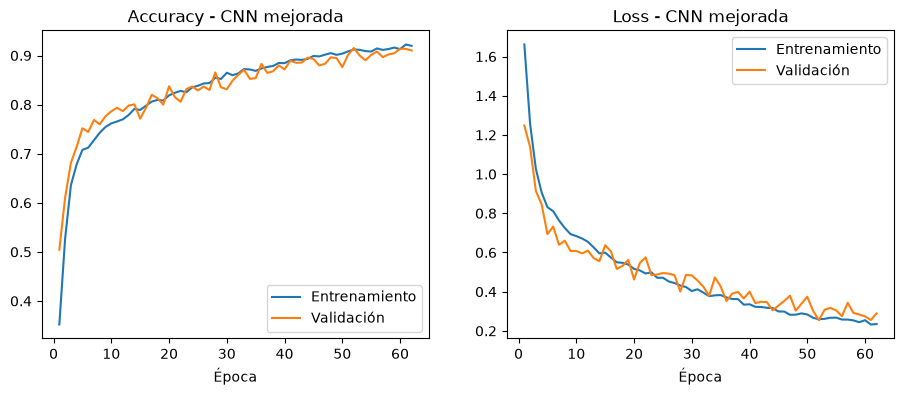

In [14]:
graficar_historial(historial_mejorado, "CNN mejorada")

In [15]:
modelo_mejorado = keras.models.load_model("mejor_modelo_mejorado.keras")

El entrenamiento frenó en la época 62 debido a que la val_accuracy no mejoraba. Se ha almacenado el mejor modelo en la variable **mejor_modelo_mejorado**, que se corresponde al de la época 52.

En este modelo, la accuracy de entrenamiento (~91,2%) quedó apenas por debajo de la de validación (~91,6%). Es esperable ya que Dropout y Data Augmentation hacen más difícil el entrenamiento, pero reducen el overfitting.

### 5. Evaluación de los dos modelos con el conjunto de testeo

#### Modelo base

In [16]:
y_pred_base = np.argmax(mejor_modelo.predict(X_test), axis=1)
print("Accuracy CNN base:", accuracy_score(y_test, y_pred_base))

169/169 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step
Accuracy CNN base: 0.7894444444444444


#### Modelo mejorado (Dropout + Data Augmentation)

In [17]:
y_pred_mejorado = np.argmax(modelo_mejorado.predict(X_test), axis=1)
print("Accuracy CNN mejorada:", accuracy_score(y_test, y_pred_mejorado))

169/169 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step
Accuracy CNN mejorada: 0.9112962962962963


### 6. Métricas de los modelos

#### Modelo base

In [18]:
print(classification_report(y_test, y_pred_base, target_names=dataset.classes, digits=3))

                      precision    recall  f1-score   support

          AnnualCrop      0.801     0.843     0.821       600
              Forest      0.920     0.955     0.937       600
HerbaceousVegetation      0.772     0.530     0.628       600
             Highway      0.554     0.654     0.600       500
          Industrial      0.828     0.922     0.872       500
             Pasture      0.772     0.728     0.749       400
       PermanentCrop      0.597     0.644     0.620       500
         Residential      0.879     0.978     0.926       600
               River      0.793     0.582     0.671       500
             SeaLake      0.924     0.978     0.951       600

            accuracy                          0.789      5400
           macro avg      0.784     0.781     0.778      5400
        weighted avg      0.791     0.789     0.785      5400



#### Modelo mejorado

In [19]:
print(classification_report(y_test, y_pred_mejorado, target_names=dataset.classes, digits=3))

                      precision    recall  f1-score   support

          AnnualCrop      0.927     0.908     0.918       600
              Forest      0.976     0.962     0.969       600
HerbaceousVegetation      0.913     0.818     0.863       600
             Highway      0.924     0.800     0.857       500
          Industrial      0.939     0.900     0.919       500
             Pasture      0.901     0.912     0.907       400
       PermanentCrop      0.828     0.888     0.857       500
         Residential      0.867     1.000     0.929       600
               River      0.875     0.922     0.898       500
             SeaLake      0.962     0.980     0.971       600

            accuracy                          0.911      5400
           macro avg      0.911     0.909     0.909      5400
        weighted avg      0.913     0.911     0.911      5400



### 7. Conclusión

El **Modelo mejorado** (con *Dropout* y *Data Augmentation*) muestra una mejora sustancial en el rendimiento general sobre el conjunto de prueba:

* **Accuracy general:** aumentó del 78.9% al 91.1% (+12.2%)
* **Métricas globales:** el *F1-score (macro avg)* se incrementó de 0.778 a 0.909, lo que refleja una clasificación mucho más equilibrada y sólida en todas las clases
* **Mejoras clave por clase:** clases que presentaban bajo desempeño en el modelo base como *Highway* (F1: 0.600 → 0.857), *HerbaceousVegetation* (F1: 0.628 → 0.863) y *PermanentCrop* (F1: 0.620 → 0.857) tuvieron un incremento drástico en su capacidad de generalización

Conclusión: la incorporación de técnicas de regularización y aumento de datos resolvió eficazmente el problema de **overfitting**, logrando un modelo más robusto y con mayor precisión en la clasificación de imágenes de cobertura terrestre.

# Modelo 2: Redes Neuronales con la implementación de Transfer Learning

Ahora se modelará una red neuronal mediante la implementación de **Transfer Learning**. Se emplea esta técnica ya que es muy utilizada actualmente en visión por computadora. Consiste en aprovechar los conocimientos de un modelo previamente entrenado con grandes cantidades de imágenes y adaptarlo al dataset del proyecto. Esto permite aprovechar características visuales ya aprendidas y mejorar el rendimiento de la clasificación.

Se utiliza **MobileNetV2**, una red convolucional liviana preentrenada con ImageNet (más de un millón de imágenes en 1000 clases). El modelo se arma de la siguiente manera:

- `include_top=False`: se descarta el clasificador original de ImageNet y se conserva solo la parte que extrae características.
- `base.trainable = False`: los pesos de MobileNetV2 se congelan, por lo que solo se entrena la parte nueva.
- `RandomFlip`: aumento de datos (giros horizontales y verticales) durante el entrenamiento.
- `Rescaling(1./127.5, offset=-1)`: lleva los píxeles de [0, 255] a [-1, 1], que es la escala que espera MobileNetV2.
- `GlobalAveragePooling2D`: resume cada mapa de características en un único valor.
- `Dropout(0.3)` y `Dense(10)`: clasificador final para las 10 clases de EuroSAT (salida en logits).
- `EarlyStopping` con paciencia de 5 épocas, restaurando los mejores pesos.

### 1. Creación del modelo 
### Versión 1: imágenes de 64×64

In [20]:
def entrenar_transfer(X_train, y_train, X_val, y_val, epochs=20):
    keras.utils.set_random_seed(1)

    base = MobileNetV2(input_shape=(64, 64, 3), include_top=False, weights="imagenet")
    base.trainable = False   # congelada: no se reentrena

    inputs = keras.Input(shape=(64, 64, 3))
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.Rescaling(1./127.5, offset=-1)(x) # escala 0-255 a [-1, 1], lo que espera MobileNetV2
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10)(x) # logits
    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"]
    )

    early = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=5, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=64,
        callbacks=[early]
    )
    return history.history, model

### 2. Entrenamiento del modelo (Versión 1)

In [21]:
historial_transfer, modelo_transfer = entrenar_transfer(X_train, y_train, X_val, y_val)

Epoch 1/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 32s 104ms/step - accuracy: 0.6938 - loss: 0.9406 - val_accuracy: 0.8393 - val_loss: 0.5260
Epoch 2/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 27s 105ms/step - accuracy: 0.8232 - loss: 0.5503 - val_accuracy: 0.8585 - val_loss: 0.4540
Epoch 3/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 24s 96ms/step - accuracy: 0.8448 - loss: 0.4803 - val_accuracy: 0.8654 - val_loss: 0.4296
Epoch 4/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 28s 109ms/step - accuracy: 0.8528 - loss: 0.4485 - val_accuracy: 0.8678 - val_loss: 0.4133
Epoch 5/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 26s 102ms/step - accuracy: 0.8562 - loss: 0.4372 - val_accuracy: 0.8693 - val_loss: 0.4123
Epoch 6/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 26s 101ms/step - accuracy: 0.8613 - loss: 0.4266 - val_accuracy: 0.8696 - val_loss: 0.4047
Epoch 7/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 24s 95ms/step - accuracy: 0.8667 - loss: 0.3995 - val_accuracy: 0.8706 - val_loss: 0.4083
Epoch 8/20
254/254 ━━━━━━━━━━━━━━━━━━━━ 27s 106ms/step - accuracy: 0.8686 - loss: 0.3

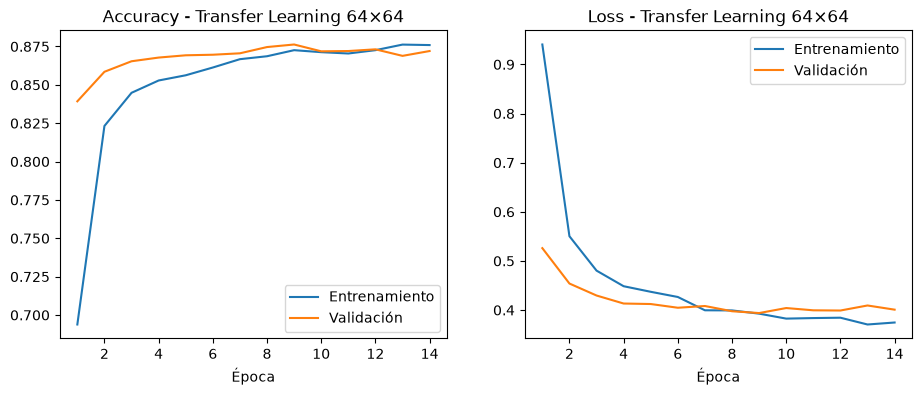

In [22]:
graficar_historial(historial_transfer, "Transfer Learning 64×64")

In [23]:
modelo_transfer.save("transfer_64.keras")

La Versión 1 (o Modelo base) de Transfer Learning con imágenes de 64x64 px alcanza un buen nivel de generalización sin overfitting (accuracy de validación alrededor del 87.6% y val_loss en torno a 0.39, alcanzados en la época 9). 

Sin embargo, dado que la red preentrenada fue diseñada originalmente para trabajar con resoluciones mayores, el tamaño de 64x64 px limita el nivel de detalle que puede aprovechar. Para optimizar la extracción de características y mejorar el rendimiento, se procederá a redimensionar las imágenes a una resolución superior en la siguiente versión.

### 3. Creación de otro modelo mejorado

### Versión 2: imágenes ampliadas a 128×128

MobileNetV2 fue entrenada con imágenes de 224×224. Con entradas de 64×64, la accuracy en la validación se estancó en 0.876. Para mejorar el rendimiento se agrega una capa `Resizing(128, 128)` dentro del modelo, de modo que los datos originales no se modifican. El resto de la arquitectura es igual a la de la Versión 1, y se agrega `ModelCheckpoint` para guardar el mejor modelo. Con este cambio, la accuracy sube a ~0.93.

In [24]:
def entrenar_transfer_128(X_train, y_train, X_val, y_val, epochs=40):
    keras.utils.set_random_seed(1)

    base = MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input(shape=(64, 64, 3)) # los datos siguen siendo 64x64
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.Resizing(128, 128)(x) # agranda a 128x128 dentro del modelo
    x = layers.Rescaling(1./127.5, offset=-1)(x) # 0-255 -> [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10)(x) # logits
    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"]
    )

    early = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=5, restore_best_weights=True)

    checkpoint = ModelCheckpoint(
        "transfer_128.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=64,
        callbacks=[early, checkpoint]
    )
    return history.history, model

### 4. Entrenamiento del modelo (Versión 2)

In [25]:
historial_transfer128, modelo_transfer128 = entrenar_transfer_128(X_train, y_train, X_val, y_val)

Epoch 1/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 81s 295ms/step - accuracy: 0.8098 - loss: 0.5617 - val_accuracy: 0.8961 - val_loss: 0.2956
Epoch 2/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 79s 313ms/step - accuracy: 0.8998 - loss: 0.2949 - val_accuracy: 0.9163 - val_loss: 0.2432
Epoch 3/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 73s 289ms/step - accuracy: 0.9140 - loss: 0.2538 - val_accuracy: 0.9224 - val_loss: 0.2235
Epoch 4/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 73s 289ms/step - accuracy: 0.9220 - loss: 0.2301 - val_accuracy: 0.9230 - val_loss: 0.2175
Epoch 5/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 75s 297ms/step - accuracy: 0.9239 - loss: 0.2183 - val_accuracy: 0.9261 - val_loss: 0.2104
Epoch 6/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 74s 291ms/step - accuracy: 0.9293 - loss: 0.2072 - val_accuracy: 0.9254 - val_loss: 0.2082
Epoch 7/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 78s 306ms/step - accuracy: 0.9329 - loss: 0.1952 - val_accuracy: 0.9246 - val_loss: 0.2100
Epoch 8/40
254/254 ━━━━━━━━━━━━━━━━━━━━ 75s 295ms/step - accuracy: 0.9336 - loss: 0

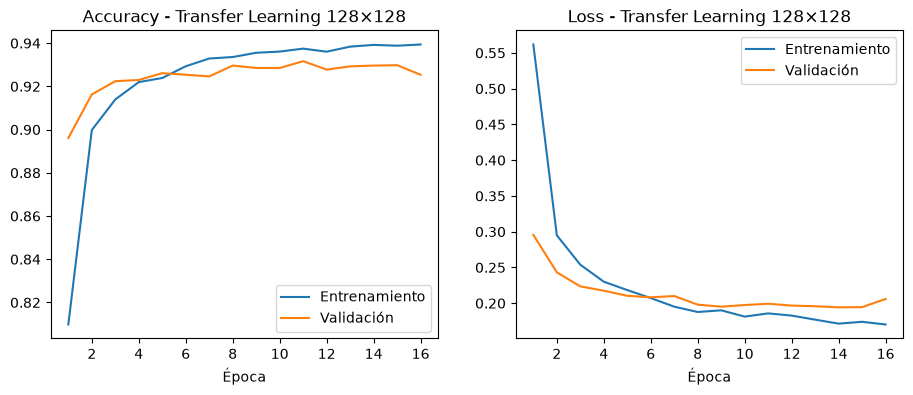

In [26]:
graficar_historial(historial_transfer128, "Transfer Learning 128×128")

In [27]:
modelo_transfer128.save("transfer_128_final.keras")

Al redimensionar las imágenes a 128x128 px, la accuracy de validación aumentó a ~93.2% (alcanzada en la época 11) y el val_loss se redujo drásticamente de ~0.39 a ~0.2. Además, la curva de validación acompaña de cerca a la de entrenamiento con una brecha mínima, lo que demuestra una excelente capacidad de generalización sin señales de overfitting.

### 5. Evaluación de los modelos con el conjunto de testeo

In [28]:
y_pred_transfer64 = np.argmax(modelo_transfer.predict(X_test), axis=1)
y_pred_transfer128 = np.argmax(modelo_transfer128.predict(X_test), axis=1)

169/169 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step
169/169 ━━━━━━━━━━━━━━━━━━━━ 22s 121ms/step


#### Modelo Base (Transfer Learning 64x64)

In [29]:
print("Accuracy (Transfer Learning 64x64):", accuracy_score(y_test, y_pred_transfer64))

print(classification_report(y_test, y_pred_transfer64, target_names=dataset.classes, digits=3))

Accuracy (Transfer Learning 64x64): 0.8722222222222222
                      precision    recall  f1-score   support

          AnnualCrop      0.892     0.925     0.908       600
              Forest      0.893     0.933     0.913       600
HerbaceousVegetation      0.852     0.832     0.841       600
             Highway      0.729     0.808     0.767       500
          Industrial      0.917     0.902     0.909       500
             Pasture      0.848     0.823     0.835       400
       PermanentCrop      0.831     0.786     0.808       500
         Residential      0.902     0.925     0.914       600
               River      0.882     0.790     0.833       500
             SeaLake      0.956     0.948     0.952       600

            accuracy                          0.872      5400
           macro avg      0.870     0.867     0.868      5400
        weighted avg      0.873     0.872     0.872      5400



#### Modelo Mejorado (Transfer Learning 128x128)

In [30]:
print("Accuracy (Transfer Learning 128x128):", accuracy_score(y_test, y_pred_transfer128))

print(classification_report(y_test, y_pred_transfer128, target_names=dataset.classes, digits=3))

Accuracy (Transfer Learning 128x128): 0.9303703703703704
                      precision    recall  f1-score   support

          AnnualCrop      0.951     0.915     0.933       600
              Forest      0.975     0.958     0.966       600
HerbaceousVegetation      0.921     0.910     0.915       600
             Highway      0.858     0.922     0.889       500
          Industrial      0.970     0.960     0.965       500
             Pasture      0.842     0.930     0.884       400
       PermanentCrop      0.911     0.862     0.886       500
         Residential      0.974     0.982     0.978       600
               River      0.881     0.876     0.879       500
             SeaLake      0.986     0.972     0.979       600

            accuracy                          0.930      5400
           macro avg      0.927     0.929     0.927      5400
        weighted avg      0.932     0.930     0.931      5400



### 6. Conclusión

Al evaluar ambos modelos sobre el conjunto de testeo, los resultados confirman el impacto directo del aumento de resolución espacial:

* **Accuracy global:** se incrementó del 87.2% (64x64) al 93.0% (128x128), ganando casi 6 puntos porcentuales de precisión en datos nunca vistos.
* **Balance entre clases (Macro F1-score):** pasó de 0.868 a 0.927, lo que demuestra una mejora uniforme y consistente en todas las categorías del dataset.
* **Mejoras destacadas por clase:**
  * *Highway:* el F1-score subió de 0.767 a 0.889.
  * *PermanentCrop:* subió de 0.808 a 0.886.
  * *Residential:* alcanzó un destacado F1-score de 0.978 (frente a 0.914 previa).

Conclusión: incrementar la resolución espacial de las imágenes confirmó ser la clave para desbloquear el potencial del modelo preentrenado, logrando el mejor desempeño de toda la práctica con redes neuronales.

# Modelo 3: Árboles de Decisión

Para abordar este problema de clasificación de imágenes mediante modelos basados en árboles de decisión, se implementarán y compararán las siguientes variantes:
- **Árbol de Decisión Base (Índice de Gini)**: se utiliza como punto de partida. Emplea el índice de Gini como criterio para medir la impureza de los nodos hijo obtenidos al dividir el nodo padre según una característica (feature) y seleccionar así las mejores divisiones.
- **Árbol de Decisión Regularizado (Poda)**: se aplica el proceso de poda, eliminando ramas que contribuyen poco a la capacidad predictiva del modelo, con el objetivo de reducir su complejidad y prevenir el sobreajuste (overfitting).
- **Random Forest**: combinación de árboles individuales. Cada árbol se entrena con una muestra aleatoria de los datos (bagging) y, en cada división, considera solo un subconjunto aleatorio de features. Esto hace que los árboles sean distintos entre sí y reduce el overfitting. La predicción final combina las de todos los árboles.

Modelos descartados:
- Entropy
- Gradient Boosting

→ No se implementaron dichos modelos, ya que el objetivo del proyecto era seleccionar y comparar algunos modelos representativos en lugar de implementar todos los disponibles.

Los árboles no procesan imágenes, sino tablas. Cada imagen de 64×64×3 se aplana en un vector de 12.288 valores (un feature por píxel y canal). Al perder la estructura espacial, estos modelos no pueden detectar bordes ni texturas, por lo que se espera un rendimiento bastante inferior al de las CNN.

In [31]:
X_train_flat = X_train.reshape(len(X_train), -1)   # (16200, 12288)
X_val_flat = X_val.reshape(len(X_val), -1)         # (5400, 12288)
X_test_flat = X_test.reshape(len(X_test), -1)      # (5400, 12288)

### 1. Árbol de Decisión Base (Índice de Gini)

In [32]:
# 1. Árbol de decisión con criterio de división Gini
tree_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
tree_gini.fit(X_train_flat, y_train)

print("Accuracy Árbol de Decisión Base (Índice de Gini)")
print("Train:", tree_gini.score(X_train_flat, y_train))
print("Val:", tree_gini.score(X_val_flat, y_val))

Accuracy Árbol de Decisión Base (Índice de Gini)
Train: 1.0
Val: 0.4590740740740741


### 2. Árbol de Decisión Regularizado (Poda)

Se aplica **poda por costo-complejidad** mediante el hiperparámetro `ccp_alpha`: cuanto mayor es su valor, más ramas se eliminan y más simple queda el árbol.

Para no elegir el valor a ojo, se usa `cost_complexity_pruning_path`, que calcula a partir del árbol completo los valores de alpha en los que se va podando una rama. Con ese rango como guía se prueban 8 valores y se elige el que obtiene mayor accuracy en el conjunto de validación (el conjunto de testeo no interviene en esta decisión).

Cantidad de valores de alpha posibles: 2500
Rango: 0.0 - 0.019568226044693937
ccp_alpha=0.000518 | train: 0.6237 | val: 0.4867
ccp_alpha=0.001000 | train: 0.5148 | val: 0.4689
Mejor ccp_alpha: 0.0005179474679231213


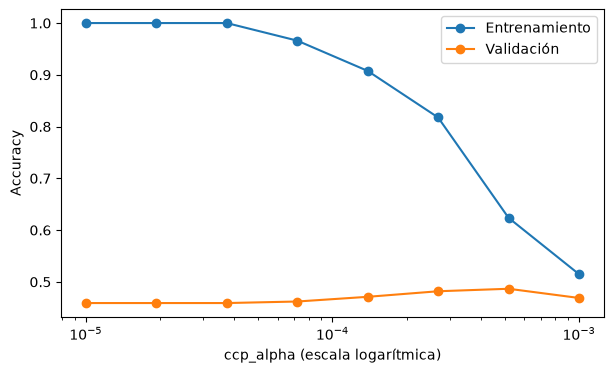

In [33]:
# 1. Valores de alpha posibles para el árbol completo
path = DecisionTreeClassifier(criterion='gini', random_state=42).cost_complexity_pruning_path(X_train_flat, y_train)
ccp_alphas = path.ccp_alphas[:-1]   # se descarta el último: deja un árbol de una sola hoja
print("Cantidad de valores de alpha posibles:", len(ccp_alphas))
print("Rango:", ccp_alphas.min(), "-", ccp_alphas.max())

# 2. Se seleccionan 8 candidatos entre 1e-5 y 1e-3 (los valores más altos podan casi todo el árbol)
alphas_candidatos = np.geomspace(1e-5, 1e-3, 8)

# 3. Se entrena un árbol por cada alpha y se mide train y validación
acc_train, acc_val = [], []
for alpha in alphas_candidatos:
    t = DecisionTreeClassifier(criterion='gini', ccp_alpha=alpha, random_state=42)
    t.fit(X_train_flat, y_train)
    acc_train.append(t.score(X_train_flat, y_train))
    acc_val.append(t.score(X_val_flat, y_val))
    print(f"ccp_alpha={alpha:.6f} | train: {acc_train[-1]:.4f} | val: {acc_val[-1]:.4f}")

# 4. Se elige el alpha con mejor accuracy en validación
mejor_alpha = alphas_candidatos[np.argmax(acc_val)]
print("Mejor ccp_alpha:", mejor_alpha)

# 5. Gráfico de alpha vs accuracy
plt.figure(figsize=(7, 4))
plt.plot(alphas_candidatos, acc_train, marker="o", label="Entrenamiento")
plt.plot(alphas_candidatos, acc_val, marker="o", label="Validación")
plt.xscale("log")
plt.xlabel("ccp_alpha (escala logarítmica)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

El valor de `ccp_alpha` elegido es el que maximizó la accuracy de validación (`mejor_alpha`). Al aumentar alpha el árbol se poda más: entrenamiento y validación se acercan (menos overfitting), pero el modelo pierde capacidad de aprendizaje, por lo que la validación empeora si alpha es demasiado grande.

In [34]:
tree_poda = DecisionTreeClassifier(criterion='gini', ccp_alpha=mejor_alpha, random_state=42)
tree_poda.fit(X_train_flat, y_train)

print("Accuracy Árbol de Decisión Regularizado (Poda)")
print("ccp_alpha:", mejor_alpha)
print("Train:", tree_poda.score(X_train_flat, y_train))
print("Val:", tree_poda.score(X_val_flat, y_val))

Accuracy Árbol de Decisión Regularizado (Poda)
ccp_alpha: 0.0005179474679231213
Train: 0.6237037037037036
Val: 0.4866666666666667


### 3. Random Forest

In [35]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_flat, y_train)

print("Accuracy Random Forest")
print("Train:", rf_model.score(X_train_flat, y_train))
print("Val:", rf_model.score(X_val_flat, y_val))

Accuracy Random Forest
Train: 1.0
Val: 0.6757407407407408


### 4. Evaluación de los modelos con el conjunto de testeo

In [36]:
# Predicciones de los árboles individuales
y_pred_gini = tree_gini.predict(X_test_flat)
y_pred_poda = tree_poda.predict(X_test_flat)

# Predicciones de los modelos de ensamblado
y_pred_rf = rf_model.predict(X_test_flat)

### 5. Métricas de los modelos

#### Árbol de Decisión Base (Índice de Gini)

In [37]:
print("Árbol Gini")
print(classification_report(y_test, y_pred_gini, target_names=dataset.classes, digits=3))

Árbol Gini
                      precision    recall  f1-score   support

          AnnualCrop      0.382     0.412     0.396       600
              Forest      0.716     0.753     0.734       600
HerbaceousVegetation      0.343     0.357     0.350       600
             Highway      0.233     0.206     0.219       500
          Industrial      0.539     0.446     0.488       500
             Pasture      0.458     0.490     0.473       400
       PermanentCrop      0.265     0.266     0.266       500
         Residential      0.378     0.370     0.374       600
               River      0.383     0.330     0.354       500
             SeaLake      0.700     0.812     0.752       600

            accuracy                          0.452      5400
           macro avg      0.440     0.444     0.441      5400
        weighted avg      0.445     0.452     0.447      5400



#### Árbol de Decisión Regularizado (Poda)

In [38]:
print("Árbol con poda")
print(classification_report(y_test, y_pred_poda, target_names=dataset.classes, digits=3))

Árbol con poda
                      precision    recall  f1-score   support

          AnnualCrop      0.391     0.475     0.429       600
              Forest      0.761     0.780     0.770       600
HerbaceousVegetation      0.360     0.397     0.377       600
             Highway      0.242     0.226     0.234       500
          Industrial      0.555     0.528     0.541       500
             Pasture      0.510     0.502     0.506       400
       PermanentCrop      0.364     0.240     0.289       500
         Residential      0.365     0.433     0.396       600
               River      0.450     0.400     0.424       500
             SeaLake      0.782     0.743     0.762       600

            accuracy                          0.481      5400
           macro avg      0.478     0.472     0.473      5400
        weighted avg      0.482     0.481     0.479      5400



#### Random Forest

In [39]:
print("Random Forest")
print(classification_report(y_test, y_pred_rf, target_names=dataset.classes, digits=3))

Random Forest
                      precision    recall  f1-score   support

          AnnualCrop      0.594     0.713     0.648       600
              Forest      0.810     0.902     0.853       600
HerbaceousVegetation      0.591     0.528     0.558       600
             Highway      0.490     0.250     0.331       500
          Industrial      0.722     0.840     0.776       500
             Pasture      0.682     0.730     0.705       400
       PermanentCrop      0.470     0.364     0.410       500
         Residential      0.549     0.653     0.597       600
               River      0.616     0.642     0.629       500
             SeaLake      0.912     0.895     0.903       600

            accuracy                          0.658      5400
           macro avg      0.644     0.652     0.641      5400
        weighted avg      0.647     0.658     0.647      5400



# Comparación final de modelos

Se comparan todos los modelos con el conjunto de testeo. Además del **accuracy**, se calcula el **F1 macro**, que promedia el F1 de las 10 clases dándole el mismo peso a cada una.

In [40]:
resultados = {
    "CNN base": y_pred_base,
    "CNN mejorada": y_pred_mejorado,
    "Transfer Learning 64×64": y_pred_transfer64,
    "Transfer Learning 128×128": y_pred_transfer128,
    "Árbol Gini": y_pred_gini,
    "Árbol con Poda": y_pred_poda,
    "Random Forest": y_pred_rf,
}

tabla = pd.DataFrame({
    "Accuracy": {m: accuracy_score(y_test, p) for m, p in resultados.items()},
    "F1 macro": {m: f1_score(y_test, p, average="macro") for m, p in resultados.items()},
}).sort_values("Accuracy", ascending=False)

tabla.round(3)

,Accuracy,F1 macro
Transfer Learning 128×128,0.930,0.927
CNN mejorada,0.911,0.909
Transfer Learning 64×64,0.872,0.868
CNN base,0.789,0.778
Random Forest,0.658,0.641
Árbol con Poda,0.481,0.473
Árbol Gini,0.452,0.441


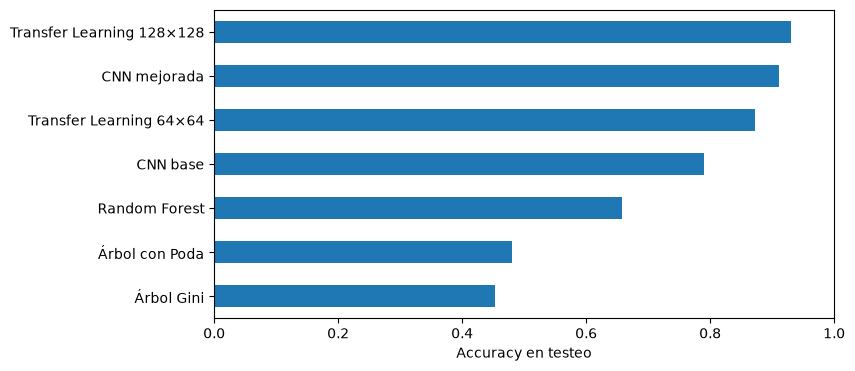

In [41]:
plt.figure(figsize=(8, 4))
tabla["Accuracy"].sort_values().plot(kind="barh")
plt.xlim(0, 1)
plt.xlabel("Accuracy en testeo")
plt.show()

### Matriz de confusión del mejor modelo

Se grafica la matriz de confusión del modelo de **Transfer Learning 128×128**, normalizada por fila: cada fila indica qué proporción de las imágenes de una clase real fue clasificada en cada clase predicha. Permite ver con qué clases se confunde el modelo.

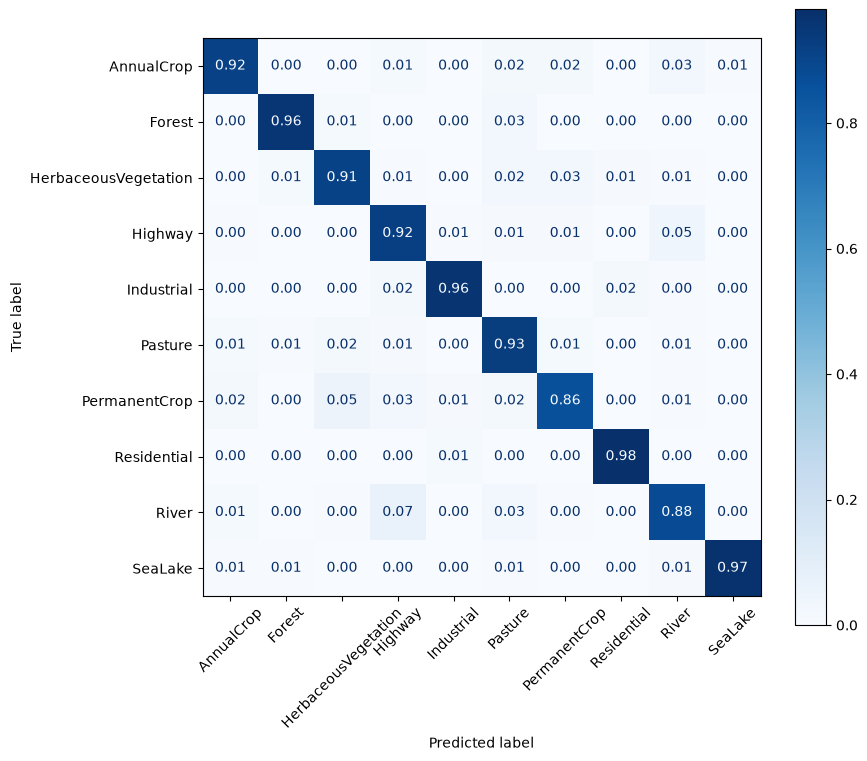

In [42]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_transfer128,
    display_labels=dataset.classes,
    normalize="true", xticks_rotation=45,
    values_format=".2f", cmap="Blues", ax=ax
)
plt.show()

### Conclusiones

- Las redes convolucionales superan ampliamente a los modelos basados en árboles. Los árboles trabajan con los píxeles aplanados y pierden la estructura espacial de la imagen, mientras que las CNN detectan bordes, texturas y patrones.
- Dentro de las CNN, Dropout y Data Augmentation mejoraron el modelo base y redujeron el overfitting.
- El mejor modelo es **Transfer Learning con MobileNetV2 y las imágenes ampliadas a 128×128** (accuracy cercano al 93% en testeo), lo que muestra el beneficio de aprovechar características aprendidas en un dataset mucho más grande.
- Entre los árboles, la poda y el Random Forest mejoran al árbol base, pero siguen muy por debajo de las redes.
- Las clases más difíciles de clasificar para el mejor modelo son `River`, `Pasture`, `PermanentCrop` y `Highway`, según se observa en la matriz de confusión y en el F1 por clase; son categorías visualmente parecidas entre sí (por ejemplo, cultivos y pasturas).